In [23]:
import pandas as pd
import numpy as np

In [24]:
df=pd.read_csv("C:/Users/Lucky_chaurasiya/Downloads/superstore_sales.csv")
df

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10795,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10796,Yes,US-2018-147998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10797,Yes,US-2018-151127,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10798,Yes,US-2018-155999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [25]:
df.columns = df.columns.str.strip()

In [26]:
df["Order Date"] = pd.to_datetime(
    df["Order Date"], format="mixed", errors="coerce"
)


In [27]:
df["Ship Date"] = pd.to_datetime(
    df["Ship Date"], format="mixed", errors="coerce"
)

In [28]:
df = df.drop_duplicates()


In [29]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
Row ID             0
Order ID           0
Order Date       302
Ship Date        302
Ship Mode        302
Customer ID      302
Customer Name    302
Segment          302
Country          302
City             302
State            302
Postal Code      313
Region           302
Product ID       302
Category         302
Sub-Category     302
Product Name     302
Sales            302
Quantity         302
Discount         302
Profit           302
dtype: int64


In [30]:
df = df[pd.to_numeric(df["Row ID"], errors="coerce").notna()].copy()

In [31]:
df = df.drop_duplicates()

In [32]:
df.to_csv("superstore_sales_clean.csv", index=False)


In [33]:
print("Original dataset cleaning complete!")
print("Final dataset shape:", df.shape)

Original dataset cleaning complete!
Final dataset shape: (9994, 21)


In [34]:
print(df.head())

  Row ID        Order ID Order Date  Ship Date       Ship Mode Customer ID  \
0      1  CA-2017-152156 2017-11-08 2017-11-11    Second Class    CG-12520   
1      2  CA-2017-152156 2017-11-08 2017-11-11    Second Class    CG-12520   
2      3  CA-2017-138688 2017-06-12 2017-06-16    Second Class    DV-13045   
3      4  US-2016-108966 2016-10-11 2016-10-18  Standard Class    SO-20335   
4      5  US-2016-108966 2016-10-11 2016-10-18  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  ...  \
0      Claire Gute   Consumer  United States        Henderson  ...   
1      Claire Gute   Consumer  United States        Henderson  ...   
2  Darrin Van Huff  Corporate  United States      Los Angeles  ...   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   

  Postal Code  Region       Product ID         Category Sub-Category  \
0     42420.0   South  FUR-BO-10001798

In [35]:
print("Total Sales:", round(df["Sales"].sum(), 2))
print("Total Profit:", round(df["Profit"].sum(), 2))
print("Unique Customers:", df["Customer ID"].nunique())
print("Total Orders:", df["Order ID"].nunique())
print("Duplicate Rows:", df.duplicated().sum())

Total Sales: 2297200.86
Total Profit: 286397.02
Unique Customers: 793
Total Orders: 5009
Duplicate Rows: 0


In [43]:
# 1. Monthly sales: highest and lowest month
monthly_sales = df.groupby(
    df["Order Date"].dt.to_period("M")
)["Sales"].sum()

print("1. Monthly Sales")
print("Highest:", monthly_sales.idxmax(), round(monthly_sales.max(), 2))
print("Lowest:", monthly_sales.idxmin(), round(monthly_sales.min(), 2))


1. Monthly Sales
Highest: 2018-11 118447.82
Lowest: 2015-02 4519.89


In [44]:
# 2. Category-wise performance
category_summary = df.groupby("Category")[["Sales", "Profit"]].sum()

print("\n2. Category Performance")
print(category_summary.sort_values("Profit", ascending=False))


2. Category Performance
                       Sales       Profit
Category                                 
Technology       836154.0330  145454.9481
Office Supplies  719047.0320  122490.8008
Furniture        741999.7953   18451.2728


In [45]:
# 3. Region-wise profit
region_profit = df.groupby("Region")["Profit"].sum()

print("\n3. Regional Performance")
print(region_profit.sort_values(ascending=False))


3. Regional Performance
Region
West       108418.4489
East        91522.7800
South       46749.4303
Central     39706.3625
Name: Profit, dtype: float64


In [47]:
# 4. Discount vs Profit correlation
correlation = df["Discount"].corr(df["Profit"])

print("\n4. Discount vs Profit")
print("Correlation:", round(correlation, 3))


4. Discount vs Profit
Correlation: -0.219


In [48]:
# 5. Customer segment performance
segment_summary = df.groupby("Segment")[["Sales", "Profit"]].sum()

print("\n5. Customer Segment Performance")
print(segment_summary.sort_values("Sales", ascending=False))


5. Customer Segment Performance
                    Sales       Profit
Segment                               
Consumer     1.161401e+06  134119.2092
Corporate    7.061464e+05   91979.1340
Home Office  4.296531e+05   60298.6785


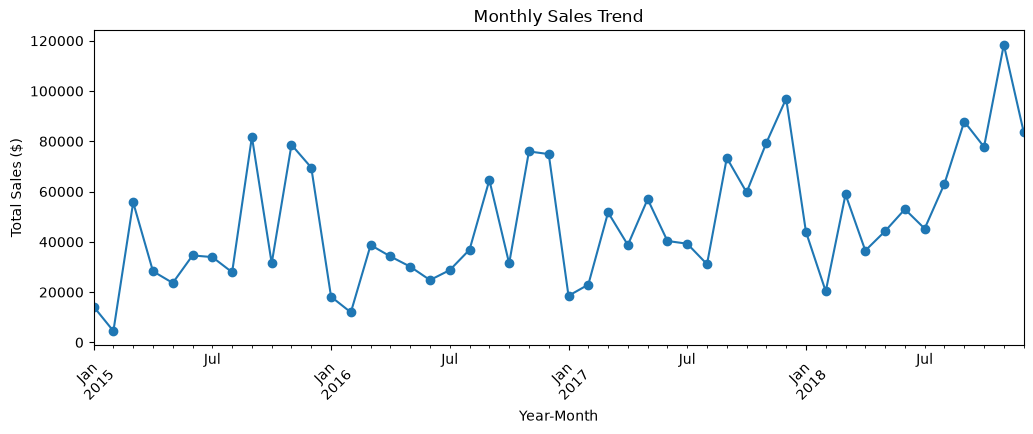

In [38]:
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams["font.family"] = "DejaVu Sans"
mpl.rcParams["font.sans-serif"] = ["DejaVu Sans"]
mpl.rcParams["font.enable_last_resort"] = False

plt.figure(figsize=(12, 5))
monthly_sales.plot(marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Year-Month")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=45)
plt.subplots_adjust(bottom=0.25)
plt.show()

                       Sales       Profit
Category                                 
Technology       836154.0330  145454.9481
Furniture        741999.7953   18451.2728
Office Supplies  719047.0320  122490.8008


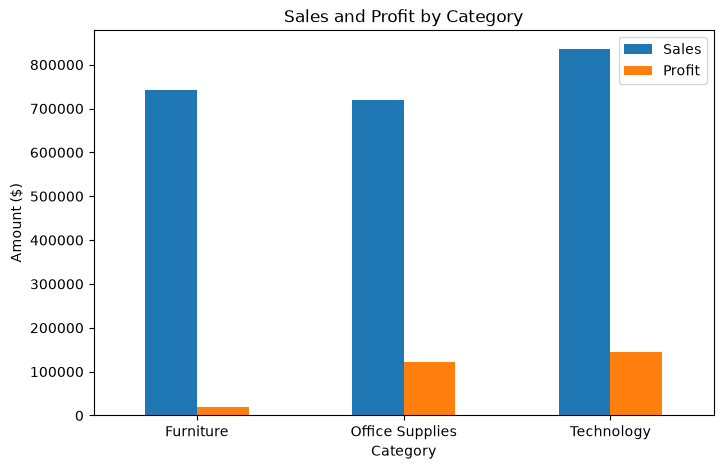

In [40]:
category_analysis = df.groupby("Category")[["Sales", "Profit"]].sum()
print(category_analysis.sort_values("Sales", ascending=False))
category_analysis.plot(kind="bar", y=["Sales", "Profit"], figsize=(8, 5))
plt.title("Sales and Profit by Category")
plt.xlabel("Category")
plt.ylabel("Amount ($)")
plt.xticks(rotation=0)
plt.show()

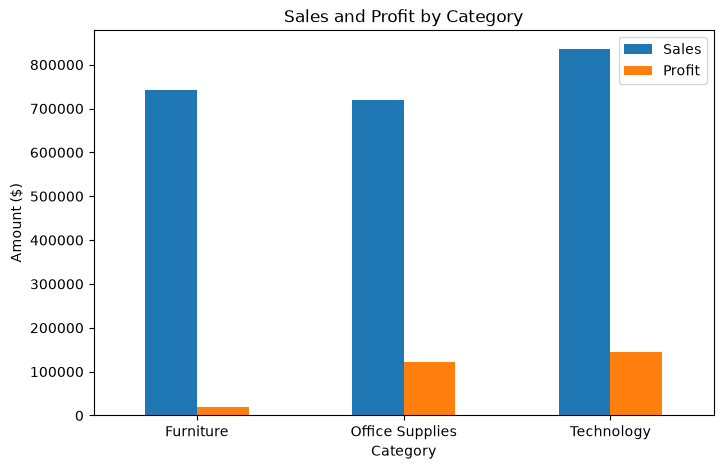

In [41]:
category_analysis.plot(kind="bar", y=["Sales", "Profit"], figsize=(8, 5))
plt.title("Sales and Profit by Category")
plt.xlabel("Category")
plt.ylabel("Amount ($)")
plt.xticks(rotation=0)
plt.show()

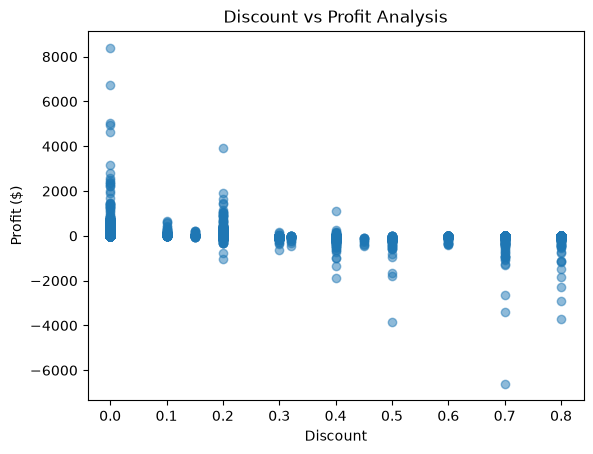

In [42]:
# Discount aur Profit ka relationship
plt.scatter(df["Discount"], df["Profit"], alpha=0.5)

plt.title("Discount vs Profit Analysis")
plt.xlabel("Discount")
plt.ylabel("Profit ($)")
plt.show()